# ablación y paridad de exportación nativa: Comparación con métodos publicados

**Nivel:** 3 **Requisitos previos:** Ablaciones y paridad de exportación nativa nivel 1 **Tiempo de lectura:** 25 minutos

**Pregunta:** ¿Los resultados de ablación emparejados y la paridad nativa demuestran una contribución del componente?

## Objetivos

Esta lección investiga la pregunta: ¿Los resultados de ablación emparejados y la paridad nativa demuestran una contribución del componente?

## Preparación

Las versiones siguientes están fijadas en `notebooks/requirements.txt` y también constan en los metadatos de este notebook; ```bash
pip install reflexmesh==0.1.2 numpy==2.5.3 matplotlib==3.11.2 torch==2.14.1 joblib==1.6.0 gymnasium==1.4.0 scikit-learn==1.9.1 stable-baselines3==2.9.2 sb3-contrib==2.9.2
```

In [1]:
# Importa la API publicada de políticas y las dependencias fijadas de gráficos y ejecución.
import hashlib
import importlib.metadata
import json
import os
from io import BytesIO
from pathlib import Path
import matplotlib.pyplot as plt
from IPython.display import Image, display
from reflexmesh.environments import CaseSpec
from reflexmesh.evaluation.runner import aggregate, run_episode
from reflexmesh.pipeline import make_policy
from reflexmesh.planners import OllamaPlanner

for distribution in ("reflexmesh", "numpy", "matplotlib"):
    print(f"{distribution}=={importlib.metadata.version(distribution)}")


reflexmesh==0.1.2
numpy==2.5.3
matplotlib==3.11.2


## Datos
El notebook lee artefactos comprometidos del producto. Propietario: Neuraxis. Repositorio: https://github.com/fsantibanezleal/CAOS_Neuraxis. Licencia: Apache-2.0. El JSON es un artefacto experimental propio y congelado; este notebook no redistribuye datos de benchmarks externos;

Este notebook lee `data/derived/index.json` y las trazas listadas. La ejecución usa un espacio aislado de caso Reflexmesh; Para métodos aprendidos, descarga los activos públicos exactos con `python -m reflexmesh; Cli fetch-models --destination models/checkpoints --version v0; 01.000` y define `NEURAXIS_CHECKPOINTS` hacia esa carpeta; El manifiesto de publicación verifica los hashes. M09/M10 se leen desde trazas congeladas, salvo que `NEURAXIS_NOTEBOOK_MODEL` indique explícitamente un modelo Ollama local configurado;

Artefactos de esta lección:

- `data/derived/index.json` - `data/derived/research.json` - `docs/evaluation/corrected-results.json` - `data/derived/episodes/M03-C07-nominal-40000; - `data/derived/episodes/M04-C07-nominal-40000; - `data/derived/episodes/M11-C07-nominal-40000; - `data/derived/episodes/M12-C07-nominal-40000; json`

## Método

La ablación es un diagnóstico causal solo si el conjunto de tareas expone una conducta que dependa del componente removido. Las cuatro ablaciones M12 medidas igualan los 1.160 éxitos de 1.200 del método completo; por ello el protocolo actual no detecta contribución al éxito de tarea. La paridad de exportación numérica pregunta si el puntuador compilado coincide con la referencia en vectores y umbrales medidos. Esta comparación ejecuta M04 en el mismo caso, pero no convierte la paridad en evidencia de control útil, calibración robusta o novedad científica. La paridad numérica pregunta si la exportación nativa aproxima una referencia dentro de una tolerancia declarada; es un estimando distinto del éxito de tarea o la contribución causal. Registra dominio de entrada, precisión, tolerancia y error absoluto máximo; un error pequeño en estados muestreados no garantiza comportamiento seguro fuera del dominio. Una conclusión sólida separa ablación conductual, paridad numérica y resultado de extremo a extremo, y nombra la evidencia de cada una sin sustituirlas. Una extensión útil agrega entradas cercanas a límites de decisión y fuera del rango de entrenamiento, y conserva la tolerancia antes de interpretar paridad como evidencia de despliegue.

### ablación y paridad de exportación nativa · nivel 3 | Verifica la auditoría y los bytes de cada traza antes de interpretar resultados.

In [2]:
# Carga las trazas propias y verifica sus hashes; nunca modifica los artefactos canónicos.
ROOT = Path("../../../").resolve()
index_path = ROOT / "data/derived/index.json"
index_bytes = index_path.read_bytes()
index = json.loads(index_bytes)
audit = json.loads((ROOT / "data/derived/benchmark-adequacy.json").read_text(encoding="utf-8"))
assert hashlib.sha256(index_bytes).hexdigest() == audit["index_sha256"]
selected_methods = ["M03", "M04", "M11", "M12"]
trace_methods = ["M03", "M04", "M11", "M12"]
sample_case = "C07"
seed = 40000
records = {}
for method_id in trace_methods:
    row = next(
        record
        for record in index["episodes"]
        if record["method_id"] == method_id
        and record["case_id"] == sample_case
        and record["variant"] == "nominal"
        and record["seed"] == seed
    )
    trace_path = ROOT / "data/derived" / row["path"]
    trace_bytes = trace_path.read_bytes()
    assert hashlib.sha256(trace_bytes).hexdigest() == row["sha256"]
    records[method_id] = json.loads(trace_bytes)
checkpoint_dir = Path(os.environ.get("NEURAXIS_CHECKPOINTS", str(ROOT / "models/checkpoints")))
planner_model = os.environ.get("NEURAXIS_NOTEBOOK_MODEL")
planner = OllamaPlanner(planner_model) if planner_model else None
print("Trazas verificadas por hash:", len(records))


Trazas verificadas por hash: 4


### ablación y paridad de exportación nativa · nivel 3 | Ejecuta las políticas publicadas y compara la corrida

### ablación y paridad de exportación nativa · nivel 3 | Compara la secuencia completa y no solo la primera acción

### ablación y paridad de exportación nativa · nivel 3 | Recalcula resultados por variante desde todas las trazas del caso

In [3]:
# Lee todas las semillas del caso elegido y conserva cada episodio fallido en el denominador.
from collections import defaultdict

groups = defaultdict(list)
for row in index["episodes"]:
    if row["case_id"] not in (sample_case,) or row["method_id"] not in selected_methods:
        continue
    raw = (ROOT / "data/derived" / row["path"]).read_bytes()
    episode = json.loads(raw)
    groups[(row["method_id"], row["variant"])].append(int(bool(episode["metrics"]["task_success"])))
for (method_id, variant), values in sorted(groups.items()):
    print(
        method_id,
        variant,
        "éxitos=",
        sum(values),
        "episodios=",
        len(values),
        "tasa=",
        round(sum(values) / len(values), 3),
    )


M03 boundary éxitos= 10 episodios= 10 tasa= 1.0
M03 delayed_observation éxitos= 10 episodios= 10 tasa= 1.0
M03 duplicate_event éxitos= 10 episodios= 10 tasa= 1.0
M03 nominal éxitos= 10 episodios= 10 tasa= 1.0
M03 stale_conflict éxitos= 10 episodios= 10 tasa= 1.0
M03 unavailable_dependency éxitos= 10 episodios= 10 tasa= 1.0
M04 boundary éxitos= 10 episodios= 10 tasa= 1.0
M04 delayed_observation éxitos= 10 episodios= 10 tasa= 1.0
M04 duplicate_event éxitos= 10 episodios= 10 tasa= 1.0
M04 nominal éxitos= 10 episodios= 10 tasa= 1.0
M04 stale_conflict éxitos= 10 episodios= 10 tasa= 1.0
M04 unavailable_dependency éxitos= 10 episodios= 10 tasa= 1.0
M11 boundary éxitos= 10 episodios= 10 tasa= 1.0
M11 delayed_observation éxitos= 10 episodios= 10 tasa= 1.0
M11 duplicate_event éxitos= 10 episodios= 10 tasa= 1.0
M11 nominal éxitos= 10 episodios= 10 tasa= 1.0
M11 stale_conflict éxitos= 10 episodios= 10 tasa= 1.0
M11 unavailable_dependency éxitos= 10 episodios= 10 tasa= 1.0
M12 boundary éxitos= 10 e

### ablación y paridad de exportación nativa · nivel 3 | Visualiza el estrés por variante sin mezclar familias

In [4]:
# Cada punto resume las semillas de una sola variante del caso, no el benchmark completo.
import matplotlib

matplotlib.use("Agg")
import matplotlib.pyplot as plt
from IPython.display import display

variants = sorted(set(key[1] for key in groups))
fig, ax = plt.subplots(figsize=(9, 4.5), constrained_layout=True)
for method_id in selected_methods:
    rates = [
        sum(groups[(method_id, variant)]) / len(groups[(method_id, variant)])
        if groups[(method_id, variant)]
        else float("nan")
        for variant in variants
    ]
    ax.plot(variants, rates, marker="o", label=method_id)
ax.set_ylim(-0.05, 1.05)
ax.set_ylabel("Tasa de éxito verificado")
ax.set_title(sample_case + " por variante")
ax.tick_params(axis="x", rotation=25)
ax.grid(axis="y", alpha=0.25)
ax.legend()
display(fig)
plt.close(fig)


<Figure size 900x450 with 1 Axes>

### Recalcula las ablaciones emparejadas

In [5]:
# La investigación está ligada al digest del índice canónico y conserva emparejamiento por celda.
research = json.loads((ROOT / "data/derived/research.json").read_text(encoding="utf-8"))
full = next(row for row in research["core"]["methods"] if row["method_id"] == "M12")
print("M12 completo:", full["successes"], "/", full["episodes"], "| tasa=", full["success_rate"])
for name, result in research["ablations"].items():
    ablated = next(row for row in result["methods"] if row["method_id"] == "M12")
    paired = result["paired_full_minus_ablation"]
    print(
        name,
        "| éxitos=",
        ablated["successes"],
        "/",
        ablated["episodes"],
        "| diferencia emparejada=",
        paired["success_difference_left_minus_right"],
        "| bootstrap95 por semilla=",
        paired["paired_seed_bootstrap95"],
        "| tiempo de M12 menos ablación (ms)=",
        round(paired["mean_wall_difference_ms_left_minus_right"], 3),
        "| alcance=",
        paired["scope"],
    )


M12 completo: 1160 / 1200 | tasa= 0.9666666666666667
no_memory | éxitos= 1160 / 1200 | diferencia emparejada= 0.0 | bootstrap95 por semilla= [0.0, 0.0] | tiempo de M12 menos ablación (ms)= 2.588 | alcance= designed shared templates; small seed-group population; compute budgets are not equalized
no_effects | éxitos= 1160 / 1200 | diferencia emparejada= 0.0 | bootstrap95 por semilla= [0.0, 0.0] | tiempo de M12 menos ablación (ms)= 39.28 | alcance= designed shared templates; small seed-group population; compute budgets are not equalized
no_deferral | éxitos= 1160 / 1200 | diferencia emparejada= 0.0 | bootstrap95 por semilla= [0.0, 0.0] | tiempo de M12 menos ablación (ms)= 131.89 | alcance= designed shared templates; small seed-group population; compute budgets are not equalized
no_invalidation | éxitos= 1160 / 1200 | diferencia emparejada= 0.0 | bootstrap95 por semilla= [0.0, 0.0] | tiempo de M12 menos ablación (ms)= 5.0 | alcance= designed shared templates; small seed-group population; c

### Audita la paridad numérica de M03/M04

In [6]:
# La paridad numérica no demuestra seguridad, calibración de decisiones ni generalización.
for method_id, result in research["native_parity"]["results"].items():
    timing = result["warmed_latency_ms"]
    print(
        method_id,
        "| vectors=",
        result["vectors"],
        "| thresholds=",
        result["split_thresholds"],
        "| max error=",
        result["max_abs_probability_error"],
        "<=",
        result["tolerance"],
    )
    print(
        "  warmed p50/p95 ms native=",
        timing["native_cached"]["50"],
        timing["native_cached"]["95"],
        "| Python=",
        timing["python_reference"]["50"],
        timing["python_reference"]["95"],
    )
    print("  scope:", result["warmed_timing_scope"])
print(research["native_parity"]["note"])


M03 | vectors= 484 | thresholds= 76 | max error= 3.1308289294429414e-14 <= 1e-05
  warmed p50/p95 ms native= 0.009 0.0118 | Python= 0.10905000000000001 0.1334849999999999
  scope: Native: packed feature serialization + cached Rust scoring + return list; Python: fitted model predict + Platt; both exclude shared feature construction and effect execution
M04 | vectors= 484 | thresholds= 76 | max error= 3.7825163745619506e-07 <= 1e-05
  warmed p50/p95 ms native= 0.0185 0.0231 | Python= 0.2917 0.38110499999999975
  scope: Native: packed feature serialization + cached Rust scoring + return list; Python: fitted model predict + Platt; both exclude shared feature construction and effect execution
Numerical export parity, not outcome generalization or safety calibration evidence


### ablación y paridad de exportación nativa · L3 | Construir la primera política ejecutable

En la comparación emparejada de ablación y exportación nativa para C07, construye M03 para ablación y paridad de exportación nativa con la fábrica pública y conserva su contrato de observación antes de muestrear C07.

In [7]:
# Construye la primera política publicada mediante la fábrica pública.
primary_id = "M03"
primary_policy = make_policy(primary_id, checkpoint_dir, planner=planner)
print("Política principal:", primary_id)


Política principal: M03


### ablación y paridad de exportación nativa · L3 | Ejecutar el método principal en el caso indicado

En la ejecución comparativa de ablación y exportación nativa para C07, de ablación y paridad de exportación nativa, el evaluador ejecuta M03 en C07 y deriva el éxito de la poscondición independiente, no de una traza reproducida.

In [8]:
# Ejecuta la política y verifica independientemente la poscondición del caso.
primary_result = run_episode(primary_policy, CaseSpec(sample_case, "nominal", seed))
print("Éxito de tarea principal:", primary_result["metrics"]["task_success"])


Éxito de tarea principal: 1


### ablación y paridad de exportación nativa · L3 | Construir una política de comparación independiente

Crea M04 como objeto nuevo para impedir que el estado recurrente de M03 contamine la comparación

In [9]:
# Crea un objeto de política nuevo para la comparación emparejada.
secondary_id = "M04"
secondary_policy = make_policy(secondary_id, checkpoint_dir, planner=planner)
print("Política de comparación:", secondary_id)


Política de comparación: M04


### ablación y paridad de exportación nativa · L3 | Ejecutar la comparación bajo condiciones idénticas

Esta comparación de nivel 3 ejecuta M04 en el mismo C07, variante nominal y semilla, y ilustra comportamiento, no estima una tasa poblacional.

In [10]:
# Usa el mismo caso, variante y semilla para la segunda política.
secondary_result = run_episode(secondary_policy, CaseSpec(sample_case, "nominal", seed))
print("Éxito de tarea de comparación:", secondary_result["metrics"]["task_success"])


Éxito de tarea de comparación: 1


### ablación y paridad de exportación nativa · L3 | Agregar los dos episodios ejecutados

El agregador resume dos episodios ejecutados de ablación y paridad de exportación nativa, y las afirmaciones entre familias aún requieren el benchmark completo

In [11]:
# Agrega los resultados ejecutados con el evaluador descriptivo del paquete.
fresh_runs = {primary_id: primary_result, secondary_id: secondary_result}
fresh_summary = aggregate([primary_result, secondary_result])
print("Ejecuciones nuevas de políticas:", len(fresh_runs))
print("Éxitos de las ejecuciones nuevas:", sum(run["metrics"]["task_success"] for run in fresh_runs.values()))


Ejecuciones nuevas de políticas: 2
Éxitos de las ejecuciones nuevas: 2


### ablación y paridad de exportación nativa · L3 | Resultados de políticas nuevas

El gráfico siguiente se calcula con los resultados de episodios de ablación y paridad de exportación nativa recién ejecutados en C07, no se copia de un artefacto congelado

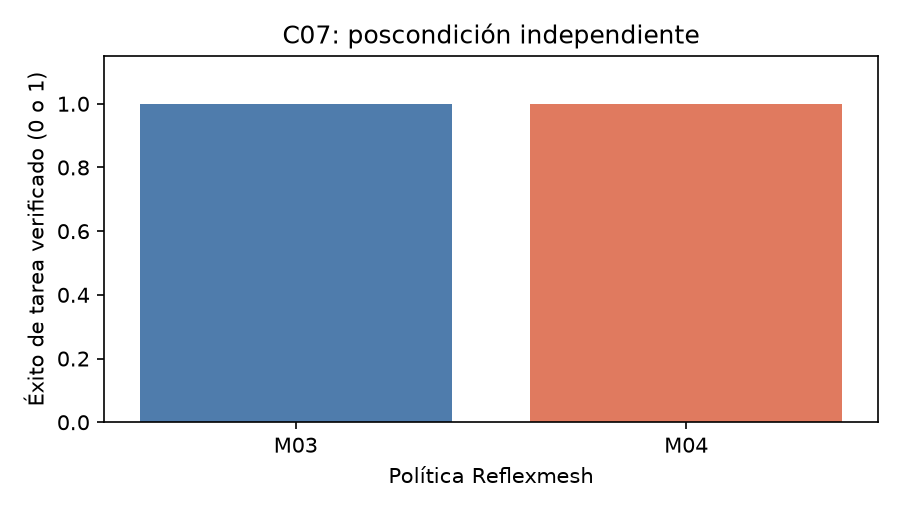

In [12]:
# Grafica los resultados verificados independientemente de las dos ejecuciones nuevas.
labels = list(fresh_runs)
success = [fresh_runs[name]["metrics"]["task_success"] for name in labels]
fig, ax = plt.subplots(figsize=(6, 3.4))
ax.bar(labels, success, color=["#4f7cac", "#e07a5f"])
ax.set_ylim(0, 1.15)
ax.set_ylabel("Éxito de tarea verificado (0 o 1)")
ax.set_xlabel("Política Reflexmesh")
ax.set_title(f"{sample_case}: poscondición independiente")
fig.tight_layout()
image_buffer = BytesIO()
fig.savefig(image_buffer, format="png", dpi=150)
display(Image(data=image_buffer.getvalue()))
image_buffer.close()
plt.close(fig)


Para ablación y paridad de exportación nativa, estas barras muestran resultados nuevos de poscondición de M03 y M04 en C07, Éxito vale 1 y falla 0. Lee el caso y la semilla antes de compararlas. En la comparación emparejada de ablación y exportación nativa para C07, este episodio controlado ilustra el comportamiento, pero no es un intervalo de confianza ni establece generalización a otras tareas de software;

## Comparación
La ablación es un diagnóstico causal solo si el conjunto de tareas expone una conducta que dependa del componente removido.

### ablación y paridad de exportación nativa · L3 | Ejecutar la referencia XGBoost bajo condiciones emparejadas

Esta llamada de referencia del nivel 3 para ablación y paridad de exportación nativa ejecuta M04 en C07 con la misma semilla nominal, y su resultado y tiempo forman una observación emparejada.

In [13]:
# Ejecuta la política XGBoost medida con la misma especificación del caso.
state_art_policy = make_policy("M04", checkpoint_dir, planner=planner)
state_art_result = run_episode(state_art_policy, CaseSpec(sample_case, "nominal", seed))
print("Ejecuciones del método de referencia:", 1)
print("Éxito de tarea de XGBoost:", state_art_result["metrics"]["task_success"])


Ejecuciones del método de referencia: 1
Éxito de tarea de XGBoost: 1


### ablación y paridad de exportación nativa · L3 | Tiempo registrado del controlador

En la ejecución comparativa de ablación y exportación nativa para C07, la figura de tiempos de ablación y paridad de exportación nativa usa registros congelados y verificados por hash para M03 y M04 en C07, no los tiempos dependientes de la máquina de episodios nuevos. Esta vista de nivel 3 para ablación y paridad de exportación nativa describe el entorno registrado bajo su caso, variante y semilla declarados.

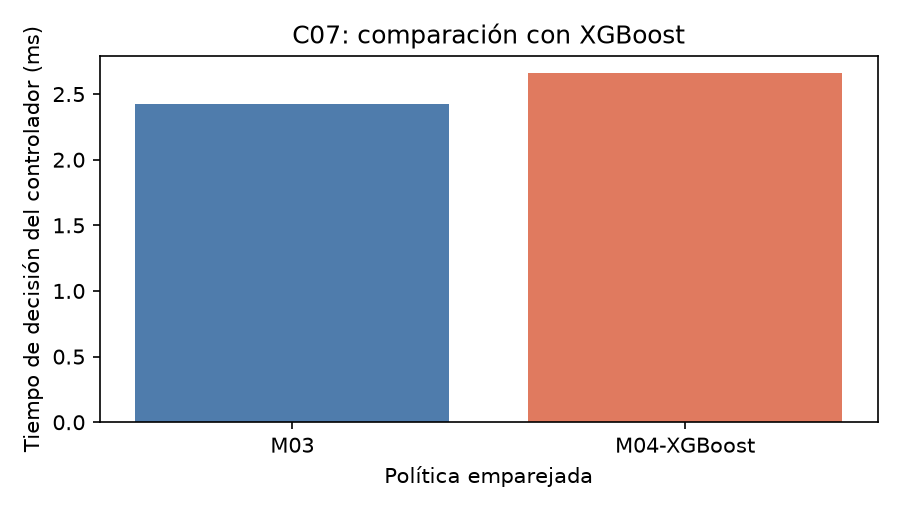

In [14]:
# Compara tiempos canónicos del controlador, verificados por hash, bajo el mismo caso, variante y semilla.
labels = [primary_id, "M04-XGBoost"]
latencies = [records[primary_id]["metrics"]["controller_ms"], records["M04"]["metrics"]["controller_ms"]]
fig, ax = plt.subplots(figsize=(6, 3.4))
ax.bar(labels, latencies, color=["#4f7cac", "#e07a5f"])
ax.set_ylabel("Tiempo de decisión del controlador (ms)")
ax.set_xlabel("Política emparejada")
ax.set_title(f"{sample_case}: comparación con XGBoost")
fig.tight_layout()
image_buffer = BytesIO()
fig.savefig(image_buffer, format="png", dpi=150)
display(Image(data=image_buffer.getvalue()))
image_buffer.close()
plt.close(fig)


La figura de nivel 3 para ablación y paridad de exportación nativa lee registros canónicos de M03/M04 en C07, variante nominal y semilla 40000, luego de verificar sus hashes en la frontera de datos. En la comparación emparejada de ablación y exportación nativa para C07, en esta lección de ablación y paridad de exportación nativa, el gráfico estable describe la latencia registrada y no afirma rapidez en la máquina actual.

## Resultados

**Respuesta:** La comparación de nivel 3 para ablación y paridad de exportación nativa contiene 2 episodios nuevos y 1 referencia XGBoost M04 en C07; esas 3 corridas emparejadas no establecen superioridad poblacional para ablación y paridad de exportación nativa.

Dentro de esta comparación de ablación y exportación nativa (C07), las cuatro ablaciones conservan los mismos 1.160/1.200 éxitos de tarea, así que este experimento no muestra contribución al éxito por memoria, efectos, aplazamiento o invalidación; En la ejecución comparativa de ablación y exportación nativa para C07, los presupuestos de ejecución difieren entre variantes, y las latencias medidas excluyen la construcción de características en Python; En la comparación emparejada de ablación y exportación nativa para C07, la paridad numérica no calibra la seguridad de la política;

En la comparación emparejada de ablación y exportación nativa para C07, este paso de autoría no compromete salidas generadas; `scripts/run_notebooks; py` las ejecuta y guarda desde un kernel nuevo.

## Resumen

Dentro de esta comparación de ablación y exportación nativa (C07), este ejemplo de ablación y paridad de exportación nativa usa C07 para mostrar el comportamiento bajo una condición declarada. En la comparación emparejada de ablación y exportación nativa para C07, mantén el resultado medido separado de afirmaciones sobre inteligencia general para controlar software.



## Referencias
- [XGB](https://arxiv.org/abs/1603.02754) - [PPO](https://arxiv.org/abs/1707.06347)